In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import nbimporter
from bike_sharing_data import get_bike_sharing

X_train, X_test, y_train, y_test = get_bike_sharing()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (13903, 12)
Testing data: (3476, 12)


In [3]:
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler

# Feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create SVR model
model = SVR(
    kernel='rbf',
    C=100,
    epsilon=0.1,
    gamma='scale'
)

# Train
model.fit(X_train_scaled, y_train.values.ravel())

print("SVR Model training completed!")

SVR Model training completed!


In [4]:
y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)

In [5]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Evaluation on testing data
mae = mean_absolute_error(y_test, y_test_pred)

mse = mean_squared_error(y_test, y_test_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_test_pred)

print("SVR Model Evaluation on Test Data")
print("-----------------------------------")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

SVR Model Evaluation on Test Data
-----------------------------------
MAE : 67.94266839532305
MSE : 12750.582773593274
RMSE: 112.9184784417204
R2 Score: 0.5973340551899481


In [6]:
train_r2 = r2_score(y_train, y_train_pred)

# Compare training and testing performance
print("Training R2:", train_r2)
print("Testing R2:", r2)

Training R2: 0.6044661698447298
Testing R2: 0.5973340551899481


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

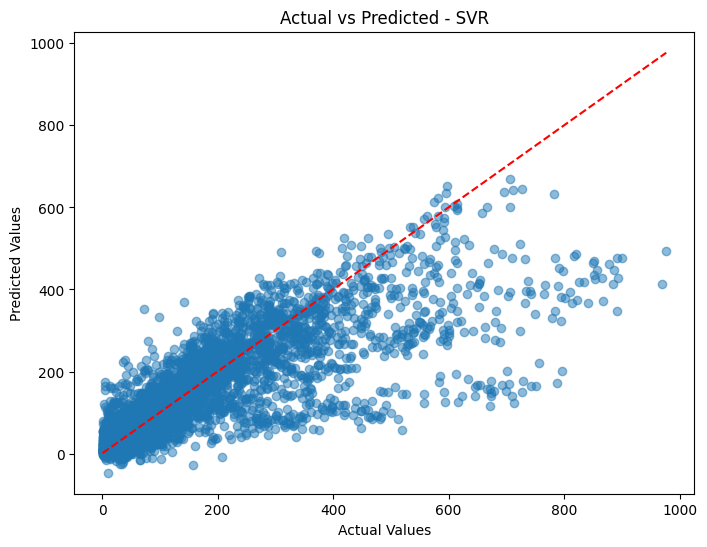

In [8]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred, alpha=0.5)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted - SVR")

plt.show()

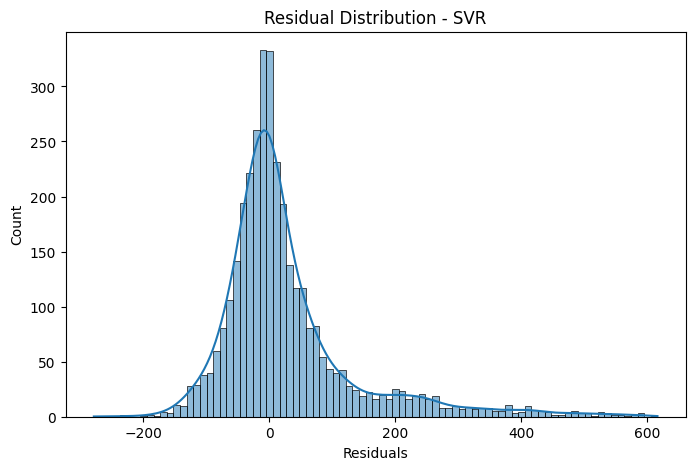

In [9]:
# Residual = Actual value - Predicted value

residuals = np.asarray(y_test).ravel() - y_test_pred

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.xlabel("Residuals")
plt.title("Residual Distribution - SVR")

plt.show()

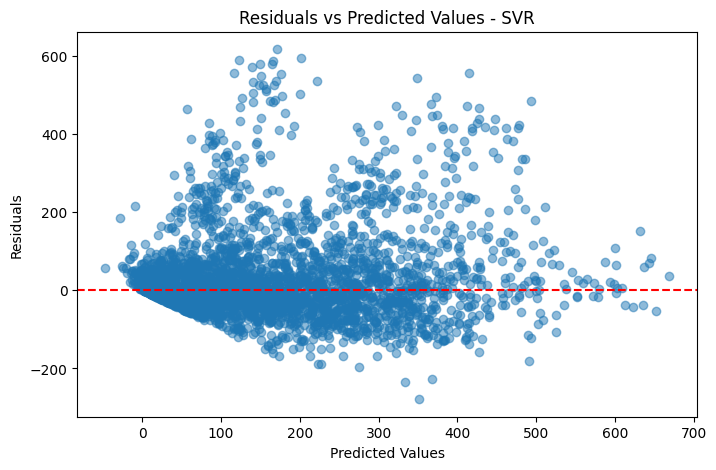

In [10]:
# Plot: Residuals vs Predicted values
plt.figure(figsize=(8, 5))

plt.scatter(y_test_pred, residuals, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values - SVR")

plt.show()

In [11]:
# Try different SVR kernels
kernels = ['linear', 'rbf', 'poly', 'sigmoid']

kernel_results = []

for kernel in kernels:

    svr = SVR(
        kernel=kernel,
        C=100,
        epsilon=0.1
    )

    svr.fit(X_train_scaled, y_train.values.ravel())

    predictions = svr.predict(X_test_scaled)

    mae = mean_absolute_error(y_test, predictions)

    mse = mean_squared_error(y_test, predictions)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, predictions)

    kernel_results.append({
        'Kernel': kernel,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

kernel_df = pd.DataFrame(kernel_results)

display(kernel_df.sort_values(by='R2 Score', ascending=False))

,Kernel,MAE,MSE,RMSE,R2 Score
1,rbf,67.942668,1.275058e+04,112.918478,0.597334
2,poly,88.167324,1.800308e+04,134.175573,0.431459
0,linear,98.940918,2.065722e+04,143.726208,0.347641
3,sigmoid,3519.294174,2.811254e+07,5302.125551,-886.799469


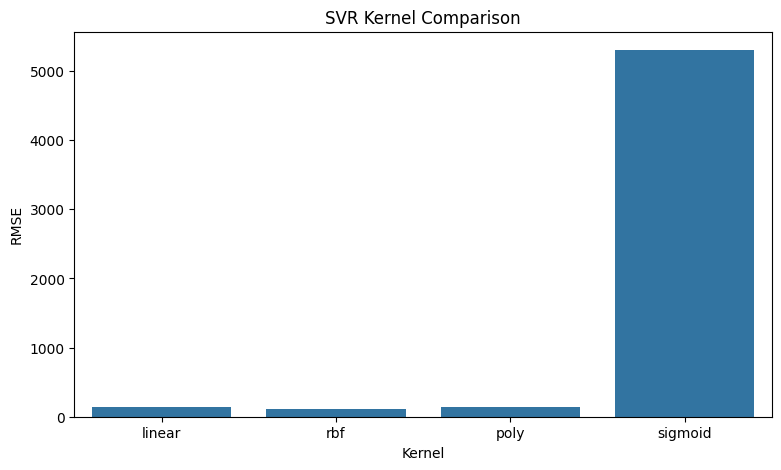

In [12]:
# Plot: SVR kernel comparison
plt.figure(figsize=(9, 5))

sns.barplot(
    data=kernel_df,
    x='Kernel',
    y='RMSE'
)

plt.title("SVR Kernel Comparison")
plt.xlabel("Kernel")
plt.ylabel("RMSE")

plt.show()